<a href="https://colab.research.google.com/github/Sameermd89/Retail-Inventory-Demand-Forecasting/blob/main/Reatil_Inventory_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

from google.colab import files

uploaded = files.upload()


Saving SQL ALL CLeaned Data OG.csv to SQL ALL CLeaned Data OG.csv


In [6]:


# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check column data types and missing values
print("\nDataset information:")
df.info()

# 4. Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 5. Display the first five records
print("\nFirst five records:")
display(df.head())


Dataset shape: (50750, 19)

Column names:
['record_id', 'sale_date', 'store_id', 'product_id', 'category', 'region', 'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast', 'price', 'discount', 'weather_condition', 'holiday_promotion', 'competitor_pricing', 'seasonality', 'supplier_id', 'lead_time_days', 'supplier_reliability']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50750 entries, 0 to 50749
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   record_id             50750 non-null  int64  
 1   sale_date             50750 non-null  object 
 2   store_id              50750 non-null  object 
 3   product_id            50750 non-null  object 
 4   category              50750 non-null  object 
 5   region                50750 non-null  object 
 6   inventory_level       50750 non-null  int64  
 7   units_sold            50750 non-null  int64  
 8   units_order

,record_id,sale_date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,weather_condition,holiday_promotion,competitor_pricing,seasonality,supplier_id,lead_time_days,supplier_reliability
0,1,13-01-23,S004,P0005,Electronics,South,268,166,188,174.79,20.70,0,Sunny,0,22.57,Winter,SUP004,10,89.6
1,2,20-09-22,S001,P0011,Clothing,North,152,99,100,98.91,46.60,15,Sunny,1,48.49,Summer,SUP006,6,81.8
2,3,12-05-23,S004,P0003,Electronics,South,153,86,72,80.17,55.17,15,Sunny,0,57.95,Summer,SUP002,20,81.7
3,4,06-04-22,S005,P0015,Electronics,North,657,381,399,392.69,58.53,0,Snowy,1,61.53,Summer,SUP005,14,91.0
4,5,16-05-22,S004,P0014,Groceries,West,98,43,45,46.45,23.28,10,Sunny,0,26.04,Winter,SUP002,15,81.5


In [8]:

# Step 3.1: Check dataset size

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Total Rows: 50750
Total Columns: 19


In [9]:

# Step 3.2: Numerical statistical summary

print("Statistical Summary")
display(df.describe().round(2))


Statistical Summary


,record_id,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,holiday_promotion,competitor_pricing,lead_time_days,supplier_reliability
count,50750.00,50750.00,50750.00,50750.00,50750.00,50750.00,50750.00,50750.0,50750.00,50750.00,50750.00
mean,25375.50,185.09,127.98,133.63,130.42,55.27,9.64,0.5,55.33,10.06,88.92
std,14650.41,131.63,96.61,102.74,99.10,25.64,7.21,0.5,25.74,5.34,5.59
min,1.00,20.00,6.00,10.00,5.00,10.00,0.00,0.0,5.34,3.00,80.60
25%,12688.25,92.00,57.00,59.00,58.29,33.57,5.00,0.0,33.76,5.00,82.70
50%,25375.50,148.00,101.00,105.00,102.80,55.20,10.00,0.0,55.19,10.00,88.50
75%,38062.75,239.00,171.00,178.00,174.82,77.25,15.00,1.0,77.19,15.00,93.90
max,50750.00,1154.00,600.00,700.00,714.66,100.00,20.00,1.0,104.74,20.00,98.20


In [13]:
# 3. Analyze important business metrics
columns = [
    "units_sold",
    "units_ordered",
    "inventory_level",
    "demand_forecast",
    "lead_time_days"
]

print("\n--- Key Business Metrics ---")

summary = df[columns].agg([
    "mean",
    "median",
    "min",
    "max",
    "std"
]).round(2)

display(summary)

# 4. Check missing values
print("\n--- Missing Values ---")
display(df[columns].isnull().sum().to_frame(
    "Missing Values"
))

print("\nStep 3.3 completed successfully!")



--- Key Business Metrics ---


,units_sold,units_ordered,inventory_level,demand_forecast,lead_time_days
mean,127.98,133.63,185.09,130.42,10.06
median,101.00,105.00,148.00,102.80,10.00
min,6.00,10.00,20.00,5.00,3.00
max,600.00,700.00,1154.00,714.66,20.00
std,96.61,102.74,131.63,99.10,5.34



--- Missing Values ---


,Missing Values
units_sold,0
units_ordered,0
inventory_level,0
demand_forecast,0
lead_time_days,0



Step 3.3 completed successfully!


CATEGORY-WISE BUSINESS SUMMARY


,category,total_units_sold,total_units_ordered,average_inventory,average_demand,total_records
0,Clothing,1293707,1352354,188.00,132.40,9962
1,Electronics,1948363,2034857,271.80,199.27,9968
2,Furniture,587475,611535,96.51,59.47,10058
3,Groceries,1716272,1791182,240.58,175.21,9981
4,Toys,855239,893846,130.27,86.96,10020
5,Unknown,93990,97862,176.12,125.46,761


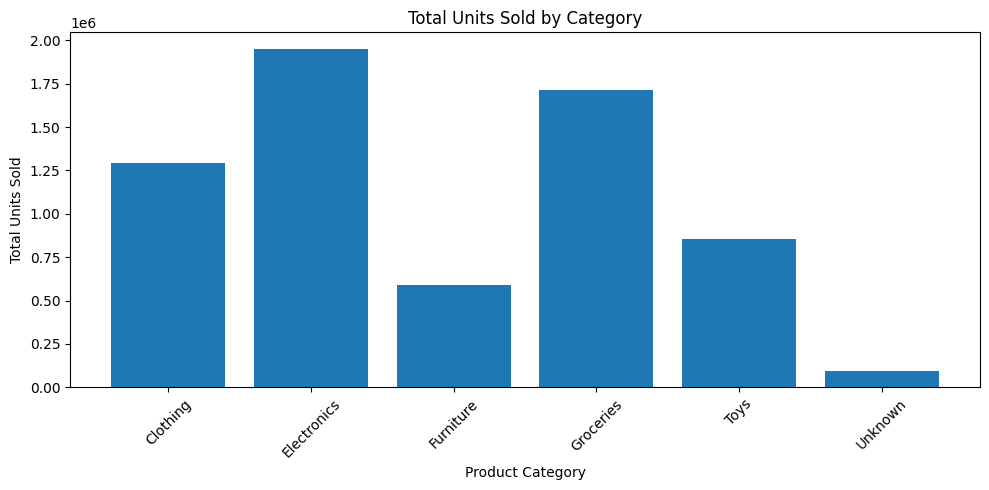

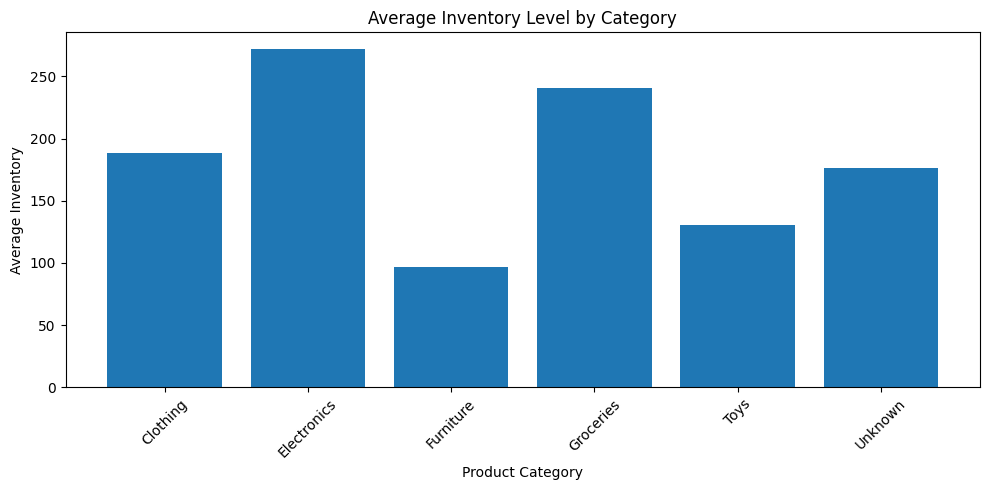

Step 4.1 completed!


In [14]:

# ==========================================
# STEP 4.1: CATEGORY-WISE BUSINESS ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Group data by product category
category_analysis = df.groupby("category").agg(
    total_units_sold=("units_sold", "sum"),
    total_units_ordered=("units_ordered", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    total_records=("record_id", "count")
).reset_index()

# 2. Round numerical results
category_analysis = category_analysis.round(2)

# 3. Display category analysis
print("CATEGORY-WISE BUSINESS SUMMARY")
display(category_analysis)

# 4. Visualize total units sold by category
plt.figure(figsize=(10, 5))
plt.bar(
    category_analysis["category"],
    category_analysis["total_units_sold"]
)
plt.title("Total Units Sold by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Visualize average inventory by category
plt.figure(figsize=(10, 5))
plt.bar(
    category_analysis["category"],
    category_analysis["average_inventory"]
)
plt.title("Average Inventory Level by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Inventory")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Step 4.1 completed!")


REGION-WISE BUSINESS SUMMARY


,region,total_units_sold,total_units_ordered,average_inventory,average_demand,total_records
0,East,1861340,1944255,207.28,148.54,12773
1,North,2162614,2257267,238.71,173.50,12702
2,South,1433697,1494527,166.94,115.60,12625
3,West,1037395,1085587,126.95,83.67,12650


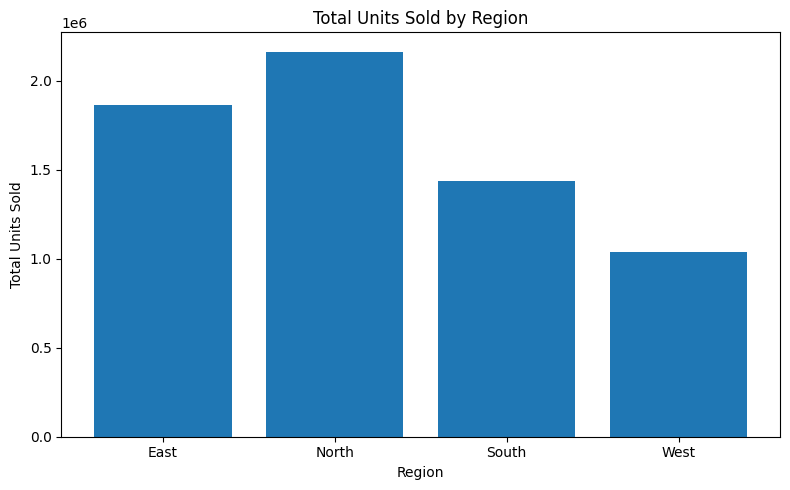

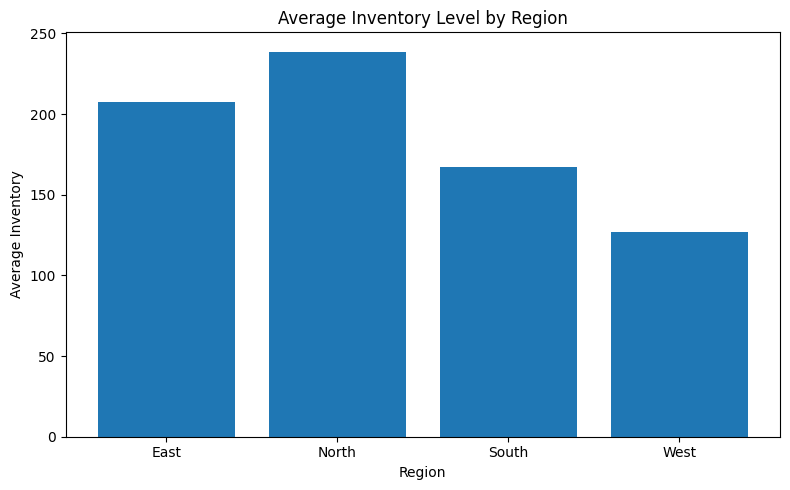

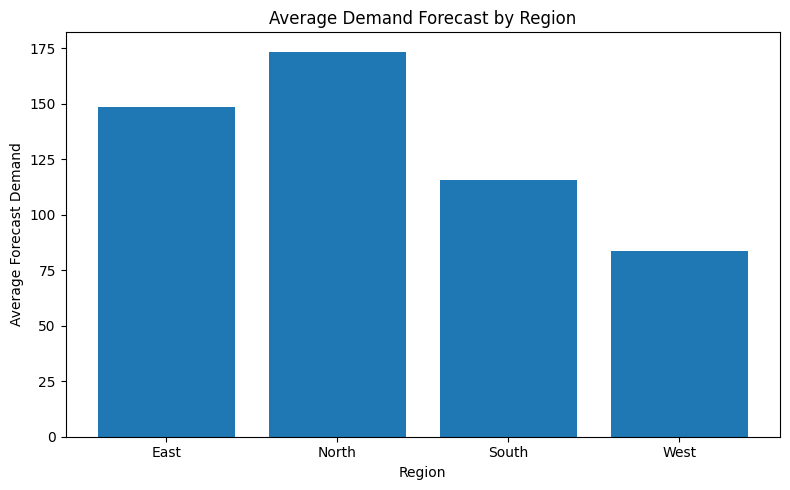

Step 4.2 completed successfully!


In [15]:

# ==========================================
# STEP 4.2: REGION-WISE BUSINESS ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Group data by region
region_analysis = df.groupby("region").agg(
    total_units_sold=("units_sold", "sum"),
    total_units_ordered=("units_ordered", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    total_records=("record_id", "count")
).reset_index()

# 2. Round numerical values
region_analysis = region_analysis.round(2)

# 3. Display the results
print("REGION-WISE BUSINESS SUMMARY")
display(region_analysis)

# 4. Chart: Total units sold by region
plt.figure(figsize=(8, 5))
plt.bar(
    region_analysis["region"],
    region_analysis["total_units_sold"]
)
plt.title("Total Units Sold by Region")
plt.xlabel("Region")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()

# 5. Chart: Average inventory by region
plt.figure(figsize=(8, 5))
plt.bar(
    region_analysis["region"],
    region_analysis["average_inventory"]
)
plt.title("Average Inventory Level by Region")
plt.xlabel("Region")
plt.ylabel("Average Inventory")
plt.tight_layout()
plt.show()

# 6. Chart: Average demand by region
plt.figure(figsize=(8, 5))
plt.bar(
    region_analysis["region"],
    region_analysis["average_demand"]
)
plt.title("Average Demand Forecast by Region")
plt.xlabel("Region")
plt.ylabel("Average Forecast Demand")
plt.tight_layout()
plt.show()

print("Step 4.2 completed successfully!")


SEASONALITY BUSINESS SUMMARY


,seasonality,total_units_sold,total_units_ordered,average_inventory,average_demand,total_records
0,Autumn,1642035,1712138,188.23,132.58,12618
1,Spring,1333447,1393074,155.72,106.77,12734
2,Summer,1504647,1570505,171.37,119.96,12783
3,Winter,2014917,2105919,225.50,162.75,12615


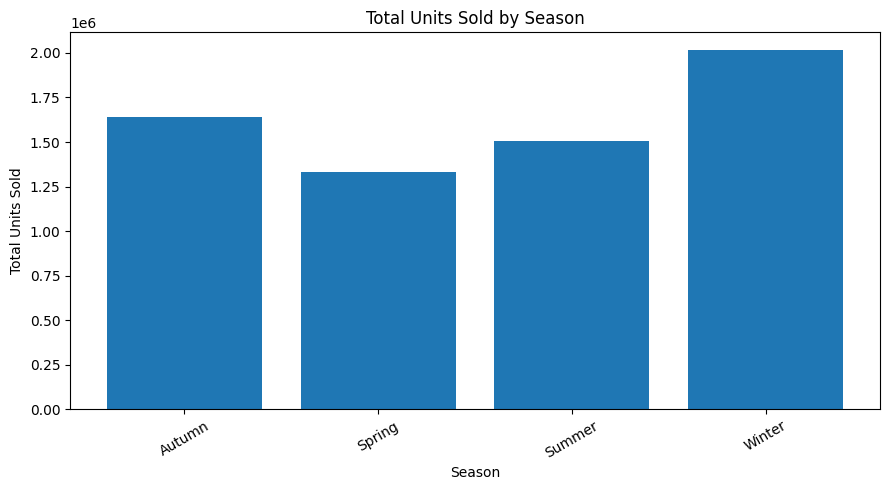

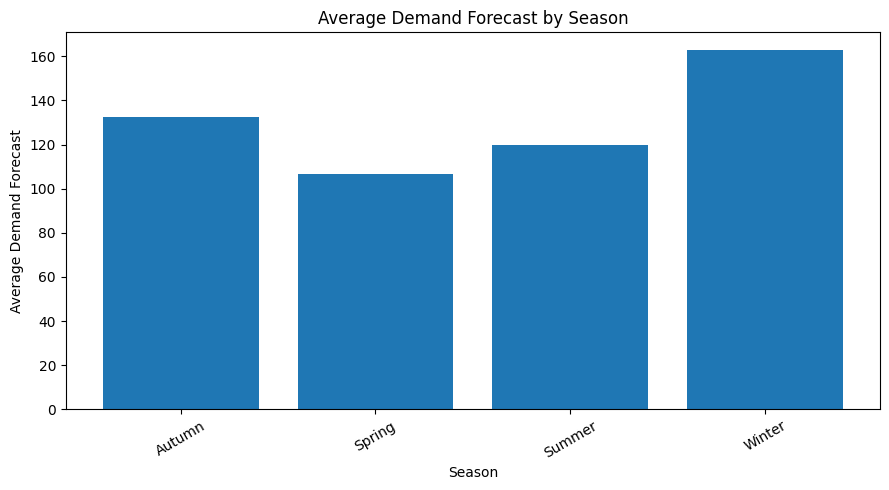

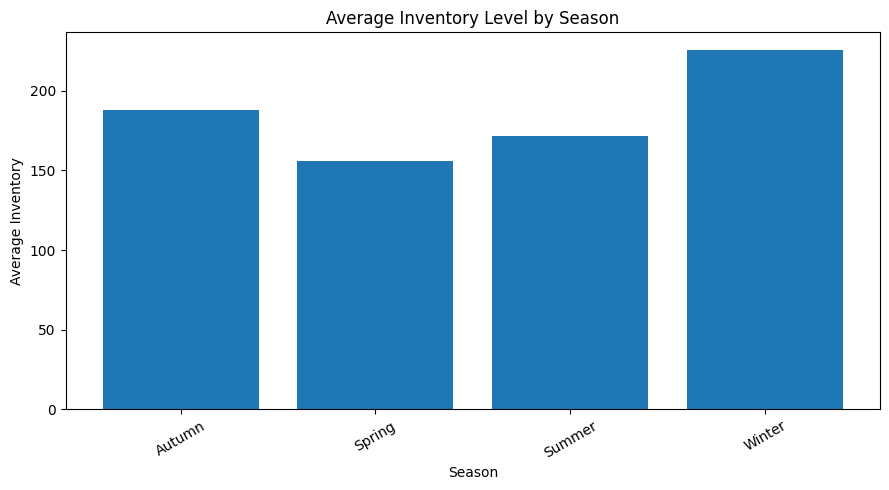

Step 4.3 completed successfully!


In [16]:

# ==========================================
# STEP 4.3: SEASONALITY ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Group data by season
season_analysis = df.groupby("seasonality").agg(
    total_units_sold=("units_sold", "sum"),
    total_units_ordered=("units_ordered", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    total_records=("record_id", "count")
).reset_index()

# 2. Round numerical values
season_analysis = season_analysis.round(2)

# 3. Display results
print("SEASONALITY BUSINESS SUMMARY")
display(season_analysis)

# 4. Chart: Total units sold by season
plt.figure(figsize=(9, 5))
plt.bar(
    season_analysis["seasonality"],
    season_analysis["total_units_sold"]
)
plt.title("Total Units Sold by Season")
plt.xlabel("Season")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 5. Chart: Average demand by season
plt.figure(figsize=(9, 5))
plt.bar(
    season_analysis["seasonality"],
    season_analysis["average_demand"]
)
plt.title("Average Demand Forecast by Season")
plt.xlabel("Season")
plt.ylabel("Average Demand Forecast")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 6. Chart: Average inventory by season
plt.figure(figsize=(9, 5))
plt.bar(
    season_analysis["seasonality"],
    season_analysis["average_inventory"]
)
plt.title("Average Inventory Level by Season")
plt.xlabel("Season")
plt.ylabel("Average Inventory")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Step 4.3 completed successfully!")


TOP 10 PRODUCTS BY TOTAL UNITS SOLD


,product_id,total_units_sold,total_units_ordered,average_inventory,average_demand,total_records
9,P0010,526419,549672,287.29,213.21,2516
17,P0018,514511,535121,279.93,206.78,2534
14,P0015,473567,495041,265.23,192.15,2511
8,P0009,455377,472400,250.01,182.44,2533
15,P0016,428826,447122,241.57,174.77,2501
11,P0012,407323,425832,228.13,165.88,2506
6,P0007,399943,417070,222.69,159.68,2556
3,P0004,372503,389684,210.10,151.13,2512
19,P0020,355434,372311,201.37,143.15,2529
1,P0002,334820,350287,191.42,134.11,2542


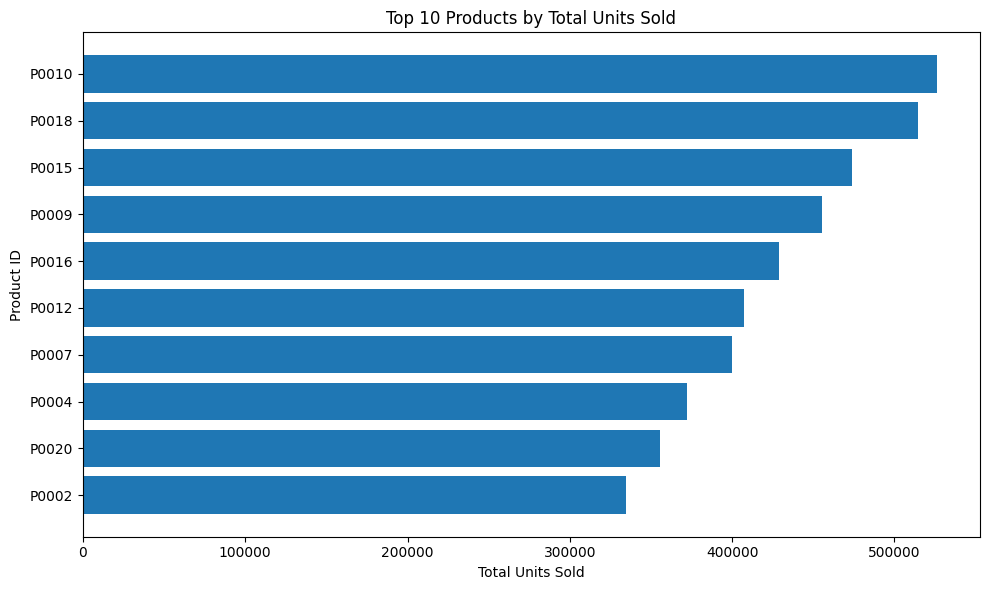

Step 4.4 completed successfully!


In [17]:

# ==========================================
# STEP 4.4: TOP 10 PRODUCTS BY SALES
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Group sales by product
product_analysis = df.groupby("product_id").agg(
    total_units_sold=("units_sold", "sum"),
    total_units_ordered=("units_ordered", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    total_records=("record_id", "count")
).reset_index()

# 2. Sort by total units sold
product_analysis = product_analysis.sort_values(
    by="total_units_sold",
    ascending=False
)

# 3. Select the top 10 products
top_10_products = product_analysis.head(10).copy()

# 4. Display results
print("TOP 10 PRODUCTS BY TOTAL UNITS SOLD")
display(top_10_products.round(2))

# 5. Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_products["product_id"].astype(str),
    top_10_products["total_units_sold"]
)

plt.title("Top 10 Products by Total Units Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Product ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Step 4.4 completed successfully!")


LOW STOCK RISK SUMMARY
Total records: 50750
Potential low-stock records: 2707
Potential low-stock percentage: 5.33 %

FIRST 10 POTENTIAL LOW-STOCK RECORDS


,record_id,store_id,product_id,category,region,inventory_level,demand_forecast,inventory_coverage_ratio
33,34,S001,P0006,Groceries,East,196,200.05,0.98
41,42,S005,P0004,Groceries,North,339,342.45,0.99
58,59,S003,P0002,Groceries,East,184,190.91,0.96
64,65,S002,P0007,Electronics,East,216,226.57,0.95
65,66,S003,P0006,Groceries,South,142,149.90,0.95
162,163,S004,P0015,Electronics,South,174,184.82,0.94
163,164,S003,P0014,Clothing,North,101,112.38,0.90
171,172,S004,P0002,Toys,South,112,118.59,0.94
184,185,S001,P0001,Furniture,North,96,101.60,0.94
193,194,S003,P0011,Electronics,East,177,179.28,0.99



POTENTIAL LOW-STOCK RECORDS BY REGION


,low_stock_records
region,
North,954
East,808
South,573
West,372


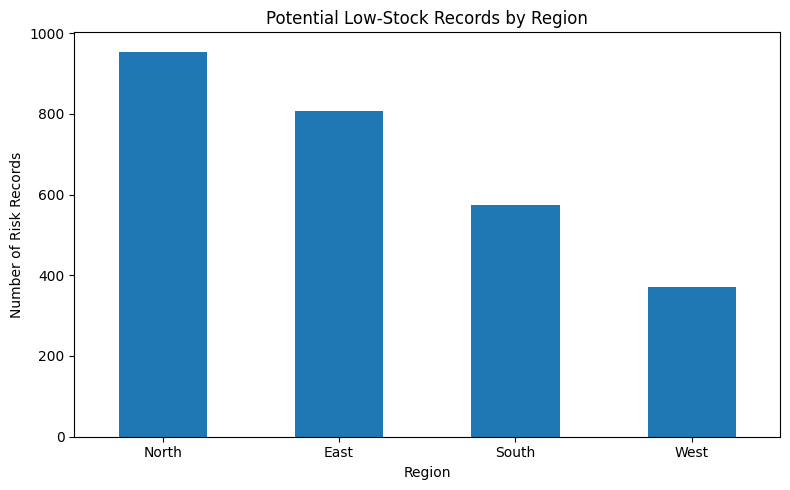


Step 4.5.1 completed!


In [18]:

# ==========================================
# STEP 4.5.1: LOW STOCK RISK ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a working copy
risk_df = df.copy()

# 2. Calculate inventory coverage ratio
# How much inventory is available compared with forecast demand
risk_df["inventory_coverage_ratio"] = (
    risk_df["inventory_level"] /
    risk_df["demand_forecast"].replace(0, float("nan"))
)

# 3. Identify potential low-stock records
# Risk rule: inventory is below forecast demand
risk_df["low_stock_risk"] = (
    risk_df["inventory_level"] < risk_df["demand_forecast"]
)

# 4. Summarize risk
total_records = len(risk_df)
risk_records = int(risk_df["low_stock_risk"].sum())
risk_percentage = (
    risk_records / total_records * 100 if total_records else 0
)

print("LOW STOCK RISK SUMMARY")
print("Total records:", total_records)
print("Potential low-stock records:", risk_records)
print("Potential low-stock percentage:", round(risk_percentage, 2), "%")

# 5. Display example risk records
print("\nFIRST 10 POTENTIAL LOW-STOCK RECORDS")

display(
    risk_df.loc[
        risk_df["low_stock_risk"],
        [
            "record_id",
            "store_id",
            "product_id",
            "category",
            "region",
            "inventory_level",
            "demand_forecast",
            "inventory_coverage_ratio"
        ]
    ].head(10).round(2)
)

# 6. Count risk records by region
risk_by_region = (
    risk_df.groupby("region")["low_stock_risk"]
    .sum()
    .sort_values(ascending=False)
)

print("\nPOTENTIAL LOW-STOCK RECORDS BY REGION")
display(risk_by_region.to_frame("low_stock_records"))

# 7. Plot risk counts by region
risk_by_region.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Potential Low-Stock Records by Region")
plt.xlabel("Region")
plt.ylabel("Number of Risk Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nStep 4.5.1 completed!")


LOW STOCK RISK BY CATEGORY


,category,total_records,low_stock_records,average_inventory,average_demand,low_stock_risk_pct
1,Electronics,9968,868,271.80,199.27,8.71
3,Groceries,9981,798,240.58,175.21,8.00
0,Clothing,9962,535,188.00,132.40,5.37
4,Toys,10020,312,130.27,86.96,3.11
2,Furniture,10058,154,96.51,59.47,1.53
5,Unknown,761,40,176.12,125.46,5.26


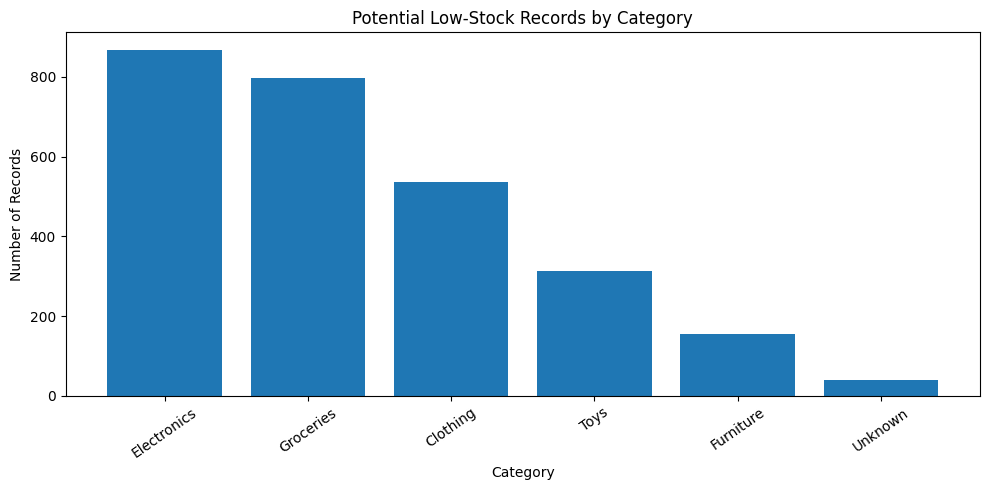

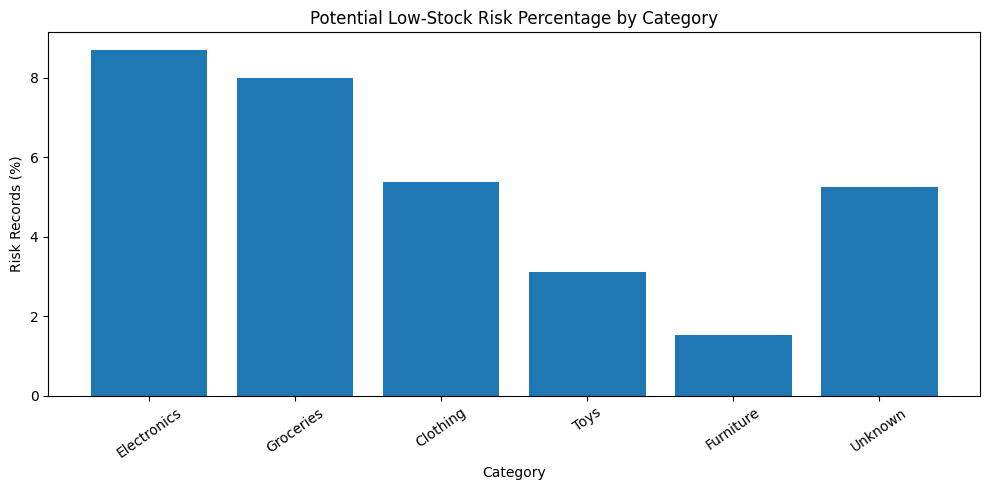

Step 4.5.2 completed successfully!


In [19]:

# ==========================================
# STEP 4.5.2: LOW STOCK RISK BY CATEGORY
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a working copy
category_risk_df = df.copy()

# 2. Identify potential low-stock records
category_risk_df["low_stock_risk"] = (
    category_risk_df["inventory_level"]
    < category_risk_df["demand_forecast"]
)

# 3. Summarize risk by category
category_risk = category_risk_df.groupby("category").agg(
    total_records=("record_id", "count"),
    low_stock_records=("low_stock_risk", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean")
).reset_index()

# 4. Calculate percentage of records at risk
category_risk["low_stock_risk_pct"] = (
    category_risk["low_stock_records"]
    / category_risk["total_records"] * 100
).round(2)

category_risk = category_risk.sort_values(
    "low_stock_risk_records" if "low_stock_risk_records" in category_risk.columns
    else "low_stock_records",
    ascending=False
)

# 5. Display results
print("LOW STOCK RISK BY CATEGORY")
display(category_risk.round(2))

# 6. Chart: Number of potential low-stock records
plt.figure(figsize=(10, 5))
plt.bar(
    category_risk["category"],
    category_risk["low_stock_records"]
)
plt.title("Potential Low-Stock Records by Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 7. Chart: Low-stock risk percentage
plt.figure(figsize=(10, 5))
plt.bar(
    category_risk["category"],
    category_risk["low_stock_risk_pct"]
)
plt.title("Potential Low-Stock Risk Percentage by Category")
plt.xlabel("Category")
plt.ylabel("Risk Records (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("Step 4.5.2 completed successfully!")


LOW STOCK RISK BY REGION


,region,total_records,low_stock_records,average_inventory,average_demand,low_stock_risk_pct
1,North,12702,954,238.71,173.50,7.51
0,East,12773,808,207.28,148.54,6.33
2,South,12625,573,166.94,115.60,4.54
3,West,12650,372,126.95,83.67,2.94


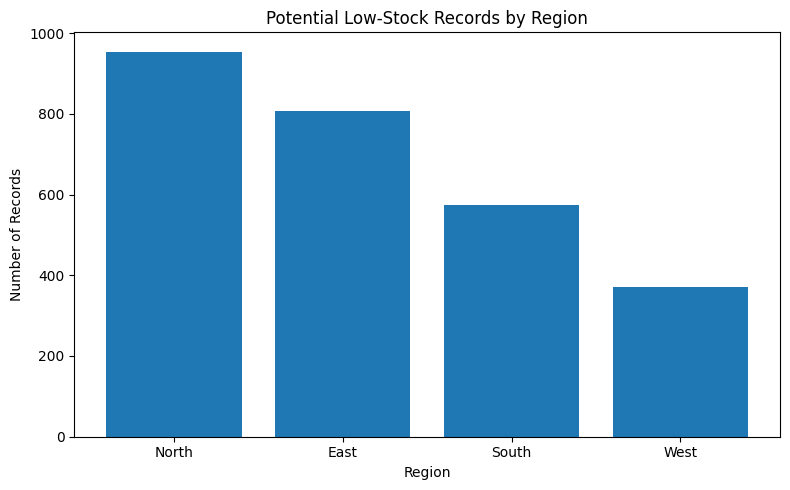

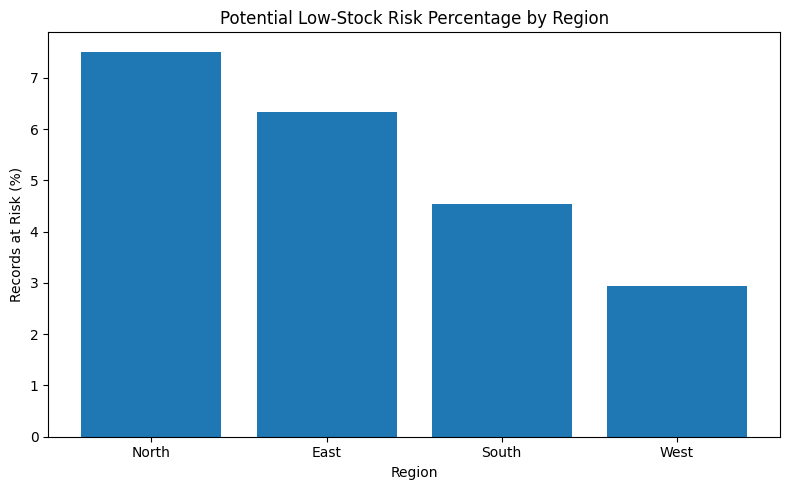

Step 4.5.3 completed successfully!


In [20]:

# ==========================================
# STEP 4.5.3: LOW STOCK RISK BY REGION
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a working copy
region_risk_df = df.copy()

# 2. Identify potential low-stock records
region_risk_df["low_stock_risk"] = (
    region_risk_df["inventory_level"]
    < region_risk_df["demand_forecast"]
)

# 3. Group records by region
region_risk = region_risk_df.groupby("region").agg(
    total_records=("record_id", "count"),
    low_stock_records=("low_stock_risk", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean")
).reset_index()

# 4. Calculate risk percentage within each region
region_risk["low_stock_risk_pct"] = (
    region_risk["low_stock_records"]
    / region_risk["total_records"] * 100
).round(2)

# 5. Sort by number of potential low-stock records
region_risk = region_risk.sort_values(
    "low_stock_records", ascending=False
)

# 6. Display results
print("LOW STOCK RISK BY REGION")
display(region_risk.round(2))

# 7. Chart: Potential low-stock records by region
plt.figure(figsize=(8, 5))
plt.bar(
    region_risk["region"],
    region_risk["low_stock_records"]
)
plt.title("Potential Low-Stock Records by Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 8. Chart: Potential low-stock percentage by region
plt.figure(figsize=(8, 5))
plt.bar(
    region_risk["region"],
    region_risk["low_stock_risk_pct"]
)
plt.title("Potential Low-Stock Risk Percentage by Region")
plt.xlabel("Region")
plt.ylabel("Records at Risk (%)")
plt.tight_layout()
plt.show()

print("Step 4.5.3 completed successfully!")


DEMAND FORECAST SUMMARY


,Metric,Value
0,Average Actual Units Sold,127.98
1,Average Forecast Demand,130.42
2,Average Forecast Difference,2.44
3,Average Absolute Difference,7.72



FORECAST VS ACTUAL SALES BY CATEGORY


,category,actual_units_sold,forecast_demand,average_difference
0,Clothing,129.86,132.40,2.54
1,Electronics,195.46,199.27,3.81
2,Furniture,58.41,59.47,1.06
3,Groceries,171.95,175.21,3.26
4,Toys,85.35,86.96,1.60
5,Unknown,123.51,125.46,1.95


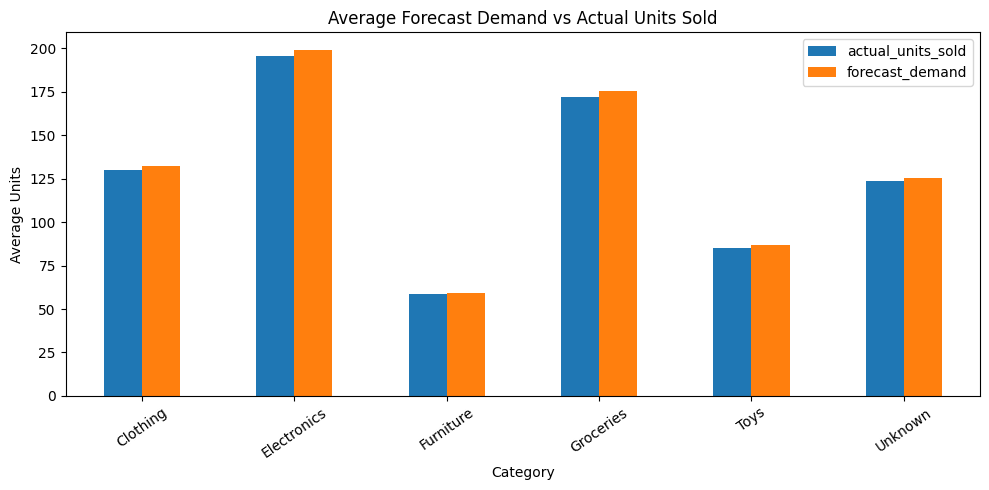


10 RECORDS WITH LARGEST FORECAST DIFFERENCES


,record_id,store_id,product_id,category,units_sold,demand_forecast,forecast_difference
34901,34902,S002,P0010,Groceries,600,714.66,114.66
13799,13800,S003,P0018,Groceries,493,379.84,-113.16
37172,37173,S001,P0009,Electronics,598,707.14,109.14
42580,42581,S002,P0010,Toys,358,462.26,104.26
21499,21500,S005,P0012,Electronics,491,594.97,103.97
29353,29354,S005,P0009,Electronics,488,591.77,103.77
15308,15309,S001,P0010,Electronics,500,601.23,101.23
47999,48000,S005,P0007,Electronics,557,456.73,-100.27
50364,50365,S005,P0010,Electronics,443,539.87,96.87
32498,32499,S003,P0010,Electronics,600,696.78,96.78



Step 4.6.1 completed successfully!


In [21]:

# ==========================================
# STEP 4.6.1: DEMAND FORECAST ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a working copy
forecast_df = df.copy()

# 2. Calculate the difference between forecast and sales
forecast_df["forecast_difference"] = (
    forecast_df["demand_forecast"] -
    forecast_df["units_sold"]
)

# 3. Calculate absolute forecast difference
forecast_df["absolute_difference"] = (
    forecast_df["forecast_difference"].abs()
)

# 4. Summarize the key metrics
print("DEMAND FORECAST SUMMARY")

summary = pd.DataFrame({
    "Metric": [
        "Average Actual Units Sold",
        "Average Forecast Demand",
        "Average Forecast Difference",
        "Average Absolute Difference"
    ],
    "Value": [
        forecast_df["units_sold"].mean(),
        forecast_df["demand_forecast"].mean(),
        forecast_df["forecast_difference"].mean(),
        forecast_df["absolute_difference"].mean()
    ]
})

display(summary.round(2))

# 5. Aggregate by category
category_forecast = forecast_df.groupby("category").agg(
    actual_units_sold=("units_sold", "mean"),
    forecast_demand=("demand_forecast", "mean"),
    average_difference=("forecast_difference", "mean")
).reset_index().round(2)

print("\nFORECAST VS ACTUAL SALES BY CATEGORY")
display(category_forecast)

# 6. Compare forecast and sales by category
category_forecast.plot(
    x="category",
    y=["actual_units_sold", "forecast_demand"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Forecast Demand vs Actual Units Sold")
plt.xlabel("Category")
plt.ylabel("Average Units")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 7. Show records with the largest forecast differences
print("\n10 RECORDS WITH LARGEST FORECAST DIFFERENCES")

display(
    forecast_df.nlargest(10, "absolute_difference")[
        [
            "record_id",
            "store_id",
            "product_id",
            "category",
            "units_sold",
            "demand_forecast",
            "forecast_difference"
        ]
    ].round(2)
)

print("\nStep 4.6.1 completed successfully!")


REORDER PRIORITY SUMMARY


,reorder_priority,total_records,average_inventory,average_demand,average_lead_time,total_stock_gap
0,Low,21709,192.99,153.57,10.30,0.00
1,Medium,2707,203.08,217.18,10.76,38156.63
2,Sufficient Stock,26334,176.73,102.42,9.80,0.00



TOP 15 RECORDS TO REVIEW


,record_id,store_id,product_id,category,inventory_level,demand_forecast,lead_time_days,stock_gap,reorder_priority
29427,29428,S002,P0009,Electronics,530,651.80,16,121.80,Medium
34112,34113,S004,P0010,Electronics,502,615.43,9,113.43,Medium
38634,38635,S002,P0010,Electronics,501,596.64,9,95.64,Medium
17215,17216,S002,P0004,Groceries,410,499.01,4,89.01,Medium
10685,10686,S003,P0018,Clothing,484,572.77,15,88.77,Medium
43795,43796,S003,P0010,Electronics,512,596.66,9,84.66,Medium
15457,15458,S002,P0007,Groceries,441,524.88,10,83.88,Medium
7351,7352,S003,P0016,Groceries,512,595.37,4,83.37,Medium
24770,24771,S001,P0016,Electronics,514,594.75,4,80.75,Medium
48703,48704,S005,P0010,Groceries,565,644.93,9,79.93,Medium


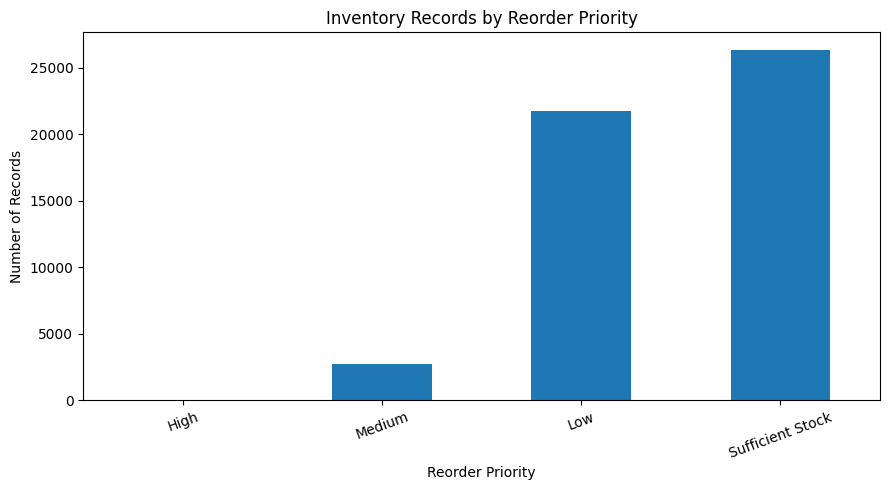


Step 4.7.1 completed successfully!


In [22]:

# ==========================================
# STEP 4.7.1: REORDER PRIORITY ANALYSIS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a working copy
reorder_df = df.copy()

# 2. Calculate inventory coverage
# Avoid division by zero
reorder_df["inventory_coverage"] = (
    reorder_df["inventory_level"]
    / reorder_df["demand_forecast"].replace(0, np.nan)
)

# 3. Calculate stock gap
# Positive gap means forecast demand exceeds inventory
reorder_df["stock_gap"] = (
    reorder_df["demand_forecast"]
    - reorder_df["inventory_level"]
).clip(lower=0)

# 4. Identify potential reorder records
reorder_df["reorder_needed"] = (
    reorder_df["stock_gap"] > 0
)

# 5. Assign priority using coverage and supplier lead time
conditions = [
    (reorder_df["inventory_coverage"] < 0.5)
    & (reorder_df["lead_time_days"] >= 15),

    (reorder_df["inventory_coverage"] < 1),

    (reorder_df["inventory_coverage"] < 1.5)
]

choices = [
    "High",
    "Medium",
    "Low"
]

reorder_df["reorder_priority"] = np.select(
    conditions,
    choices,
    default="Sufficient Stock"
)

# 6. Display priority summary
print("REORDER PRIORITY SUMMARY")

priority_summary = reorder_df.groupby(
    "reorder_priority"
).agg(
    total_records=("record_id", "count"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    average_lead_time=("lead_time_days", "mean"),
    total_stock_gap=("stock_gap", "sum")
).reset_index().round(2)

display(priority_summary)

# 7. Show highest-priority records first
priority_order = {
    "High": 1,
    "Medium": 2,
    "Low": 3,
    "Sufficient Stock": 4
}

reorder_df["priority_rank"] = (
    reorder_df["reorder_priority"].map(priority_order)
)

print("\nTOP 15 RECORDS TO REVIEW")

display(
    reorder_df.sort_values(
        ["priority_rank", "stock_gap"],
        ascending=[True, False]
    )[
        [
            "record_id",
            "store_id",
            "product_id",
            "category",
            "inventory_level",
            "demand_forecast",
            "lead_time_days",
            "stock_gap",
            "reorder_priority"
        ]
    ].head(15).round(2)
)

# 8. Visualize priority counts
priority_counts = (
    reorder_df["reorder_priority"]
    .value_counts()
    .reindex(
        ["High", "Medium", "Low", "Sufficient Stock"],
        fill_value=0
    )
)

priority_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Inventory Records by Reorder Priority")
plt.xlabel("Reorder Priority")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("\nStep 4.7.1 completed successfully!")


In [24]:

# Check inventory coverage and stock gap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

priority_df = df.copy()

priority_df["inventory_coverage"] = (
    priority_df["inventory_level"] /
    priority_df["demand_forecast"].replace(0, np.nan)
)

priority_df["stock_gap"] = (
    priority_df["demand_forecast"] -
    priority_df["inventory_level"]
).clip(lower=0)

print("Inventory Coverage Summary:")
print(priority_df["inventory_coverage"].describe())

print("\nStock Gap Summary:")
print(priority_df["stock_gap"].describe())

print("\nRecords with coverage below 0.5:")
print((priority_df["inventory_coverage"] < 0.5).sum())

print("\nRecords with coverage below 1:")
print((priority_df["inventory_coverage"] < 1).sum())


Inventory Coverage Summary:
count    50750.000000
mean         1.554426
std          0.431803
min          0.813133
25%          1.254153
50%          1.518331
75%          1.760329
max          7.966102
Name: inventory_coverage, dtype: float64

Stock Gap Summary:
count    50750.000000
mean         0.751855
std          4.635425
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        121.800000
Name: stock_gap, dtype: float64

Records with coverage below 0.5:
0

Records with coverage below 1:
2707


Overall Reorder Priority:
reorder_priority
Sufficient Stock    26334
Low                 21709
Medium               2707
Name: count, dtype: int64

Reorder Priority by Category:


reorder_priority,High,Medium,Low,Sufficient Stock
category,,,,
Clothing,0,535,4590,4837
Electronics,0,868,5021,4079
Furniture,0,154,2923,6981
Groceries,0,798,5090,4093
Toys,0,312,3748,5960
Unknown,0,40,337,384


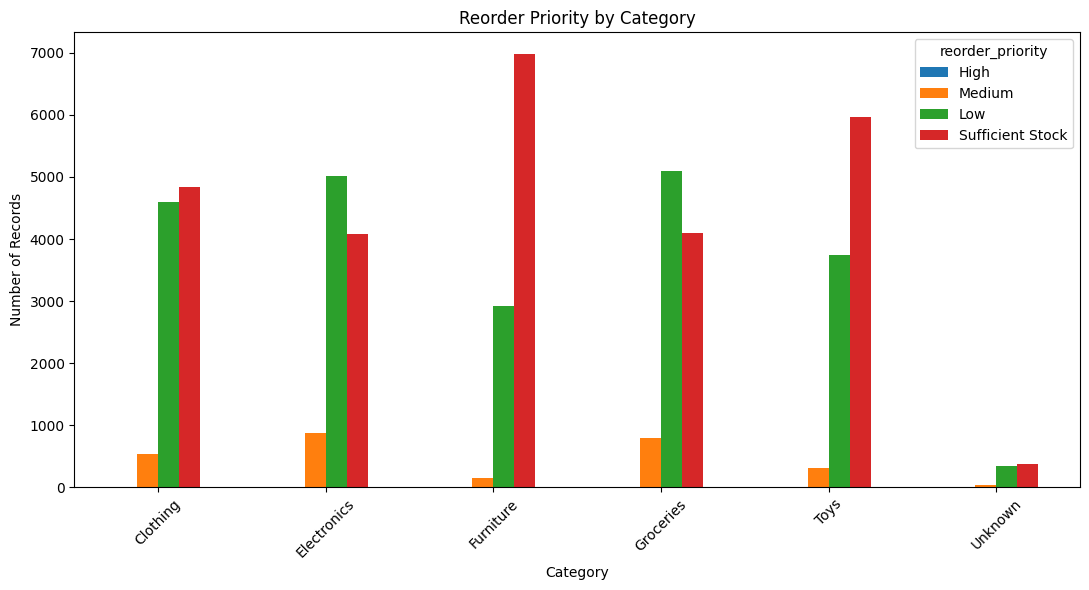


Reorder Priority by Region:


reorder_priority,High,Medium,Low,Sufficient Stock
region,,,,
East,0,808,5922,6043
North,0,954,6070,5678
South,0,573,5245,6807
West,0,372,4472,7806


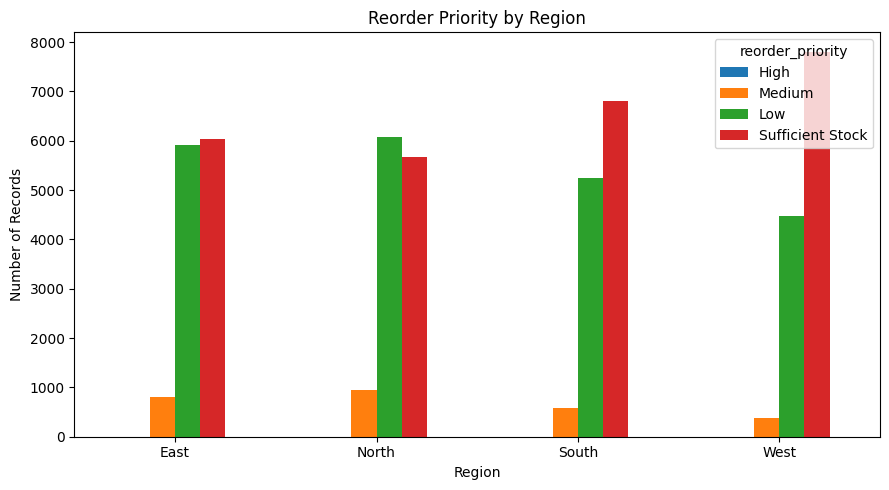

In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create a fresh copy of the dataset
priority_df = df.copy()

# Calculate inventory coverage
priority_df["inventory_coverage"] = (
    priority_df["inventory_level"] /
    priority_df["demand_forecast"].replace(0, np.nan)
)

# Assign reorder priorities
priority_df["reorder_priority"] = np.select(
    [
        priority_df["inventory_coverage"] < 0.5,
        priority_df["inventory_coverage"] < 1,
        priority_df["inventory_coverage"] < 1.5
    ],
    [
        "High",
        "Medium",
        "Low"
    ],
    default="Sufficient Stock"
)

# Check overall priority distribution
print("Overall Reorder Priority:")
print(priority_df["reorder_priority"].value_counts())

# Category-wise analysis
category_priority = pd.crosstab(
    priority_df["category"],
    priority_df["reorder_priority"]
).reindex(
    columns=["High", "Medium", "Low", "Sufficient Stock"],
    fill_value=0
)

print("\nReorder Priority by Category:")
display(category_priority)

category_priority.plot(kind="bar", figsize=(11, 6))
plt.title("Reorder Priority by Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Region-wise analysis
region_priority = pd.crosstab(
    priority_df["region"],
    priority_df["reorder_priority"]
).reindex(
    columns=["High", "Medium", "Low", "Sufficient Stock"],
    fill_value=0
)

print("\nReorder Priority by Region:")
display(region_priority)

region_priority.plot(kind="bar", figsize=(9, 5))
plt.title("Reorder Priority by Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


SUPPLIER PERFORMANCE SUMMARY


,supplier_id,total_records,average_lead_time,average_reliability,total_units_ordered,average_inventory,average_demand
0,SUP001,2550,20.00,83.800,335382,182.19,128.47
1,SUP002,15228,11.86,88.497,2023709,184.15,129.79
2,SUP003,5049,12.51,92.330,1022072,268.59,197.77
3,SUP004,7644,10.33,88.530,1017817,184.92,129.68
4,SUP005,10089,6.49,93.903,1111838,156.65,107.39
5,SUP006,5122,7.00,84.407,464064,132.26,88.65
6,SUP007,5068,7.03,84.584,806754,216.45,155.44


Suppliers with the longest average lead times:


,supplier_id,total_records,average_lead_time,average_reliability,total_units_ordered,average_inventory,average_demand
0,SUP001,2550,20.00,83.800,335382,182.19,128.47
2,SUP003,5049,12.51,92.330,1022072,268.59,197.77
1,SUP002,15228,11.86,88.497,2023709,184.15,129.79
3,SUP004,7644,10.33,88.530,1017817,184.92,129.68
6,SUP007,5068,7.03,84.584,806754,216.45,155.44
5,SUP006,5122,7.00,84.407,464064,132.26,88.65
4,SUP005,10089,6.49,93.903,1111838,156.65,107.39


Suppliers with the lowest average reliability:


,supplier_id,total_records,average_lead_time,average_reliability,total_units_ordered,average_inventory,average_demand
0,SUP001,2550,20.00,83.800,335382,182.19,128.47
5,SUP006,5122,7.00,84.407,464064,132.26,88.65
6,SUP007,5068,7.03,84.584,806754,216.45,155.44
1,SUP002,15228,11.86,88.497,2023709,184.15,129.79
3,SUP004,7644,10.33,88.530,1017817,184.92,129.68
2,SUP003,5049,12.51,92.330,1022072,268.59,197.77
4,SUP005,10089,6.49,93.903,1111838,156.65,107.39


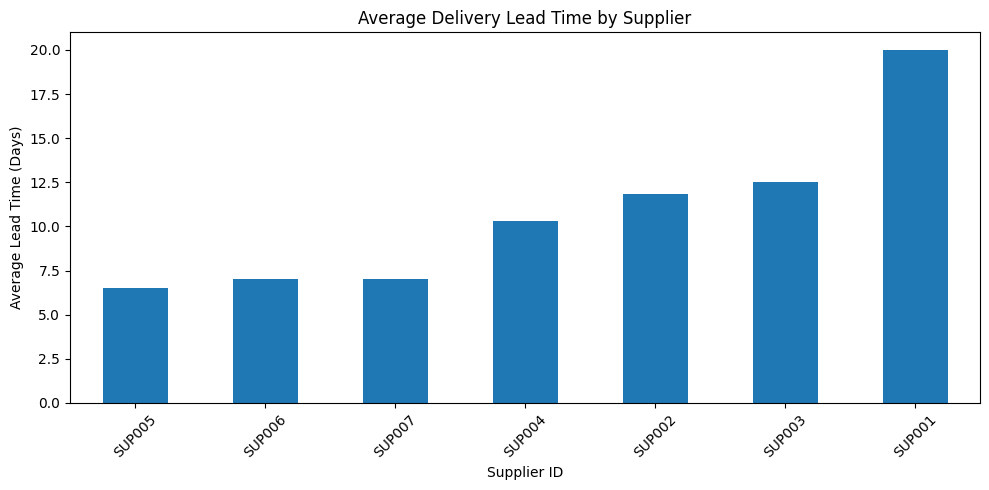

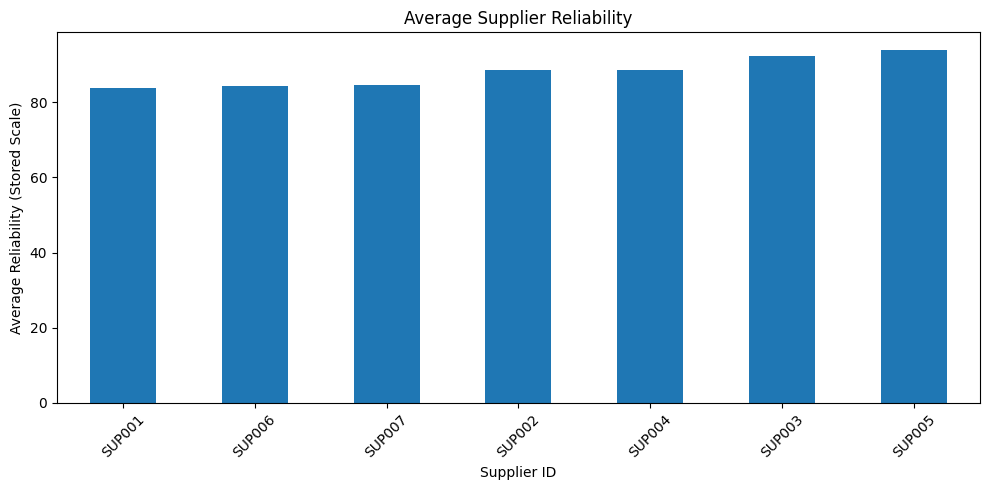

In [27]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Group the data by supplier
supplier_analysis = df.groupby("supplier_id").agg(
    total_records=("record_id", "count"),
    average_lead_time=("lead_time_days", "mean"),
    average_reliability=("supplier_reliability", "mean"),
    total_units_ordered=("units_ordered", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean")
).reset_index()

# 2. Round average values
supplier_analysis["average_lead_time"] = (
    supplier_analysis["average_lead_time"].round(2)
)
supplier_analysis["average_reliability"] = (
    supplier_analysis["average_reliability"].round(3)
)
supplier_analysis["average_inventory"] = (
    supplier_analysis["average_inventory"].round(2)
)
supplier_analysis["average_demand"] = (
    supplier_analysis["average_demand"].round(2)
)

# 3. Display supplier performance
print("SUPPLIER PERFORMANCE SUMMARY")
display(supplier_analysis)

# 4. Suppliers with the longest average lead times
print("Suppliers with the longest average lead times:")
display(
    supplier_analysis.sort_values(
        "average_lead_time", ascending=False
    ).head(10)
)

# 5. Suppliers with the lowest average reliability
print("Suppliers with the lowest average reliability:")
display(
    supplier_analysis.sort_values(
        "average_reliability", ascending=True
    ).head(10)
)

# 6. Chart: Average lead time by supplier
supplier_analysis.sort_values(
    "average_lead_time"
).plot(
    x="supplier_id",
    y="average_lead_time",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Average Delivery Lead Time by Supplier")
plt.xlabel("Supplier ID")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Chart: Average reliability by supplier
supplier_analysis.sort_values(
    "average_reliability"
).plot(
    x="supplier_id",
    y="average_reliability",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Average Supplier Reliability")
plt.xlabel("Supplier ID")
plt.ylabel("Average Reliability (Stored Scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


INVENTORY RISK SUMMARY
----------------------
Total Records: 50750
Records Below Forecast Demand: 2707
Low Stock Risk (%): 5.33 %
Total Calculated Stock Gap: 38156.63
Average Inventory Coverage: 1.55

RISK SUMMARY BY CATEGORY


,category,total_records,low_stock_records,average_inventory,average_demand,total_stock_gap,low_stock_percentage
0,Clothing,9962,535,188.00,132.40,6518.92,5.37
1,Electronics,9968,868,271.80,199.27,15722.63,8.71
2,Furniture,10058,154,96.51,59.47,638.50,1.53
3,Groceries,9981,798,240.58,175.21,11938.38,8.00
4,Toys,10020,312,130.27,86.96,2814.47,3.11
5,Unknown,761,40,176.12,125.46,523.73,5.26


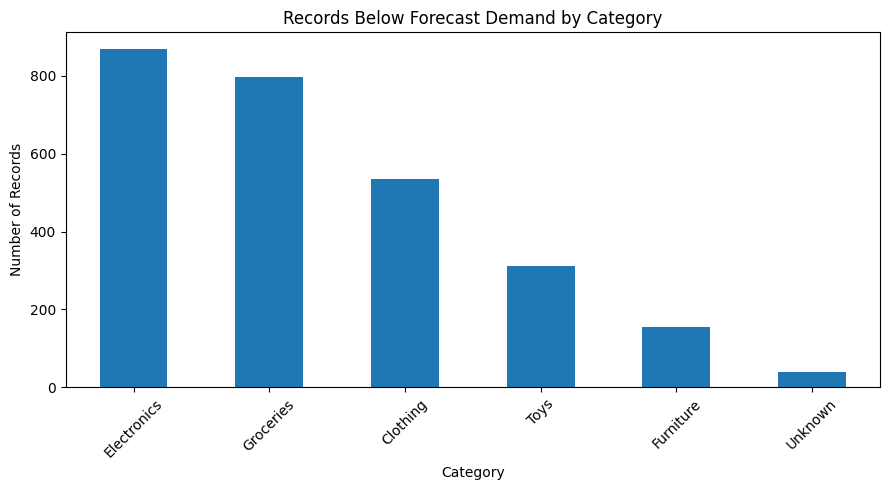


RISK SUMMARY BY REGION


,region,total_records,low_stock_records,total_stock_gap,low_stock_percentage
0,East,12773,808,11690.13,6.33
1,North,12702,954,16636.11,7.51
2,South,12625,573,6771.48,4.54
3,West,12650,372,3058.91,2.94


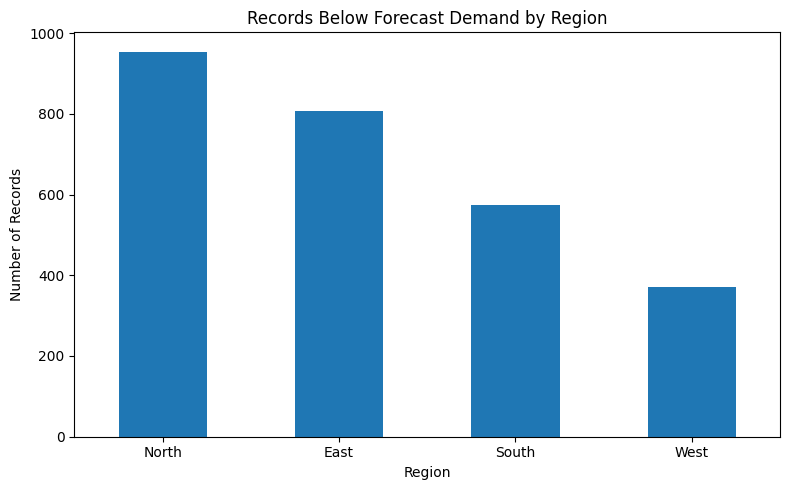

In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a copy of the dataset
risk_df = df.copy()

# 2. Calculate inventory coverage and stock gap
risk_df["inventory_coverage"] = (
    risk_df["inventory_level"] /
    risk_df["demand_forecast"].replace(0, np.nan)
)

risk_df["stock_gap"] = (
    risk_df["demand_forecast"] -
    risk_df["inventory_level"]
).clip(lower=0)

# 3. Identify records where inventory is below forecast demand
risk_df["low_stock_risk"] = (
    risk_df["inventory_level"] < risk_df["demand_forecast"]
)

# 4. Calculate summary metrics
total_records = len(risk_df)
low_stock_records = int(risk_df["low_stock_risk"].sum())
low_stock_percentage = (
    low_stock_records / total_records * 100
    if total_records > 0 else 0
)

total_stock_gap = risk_df["stock_gap"].sum()
average_coverage = risk_df["inventory_coverage"].mean()

print("INVENTORY RISK SUMMARY")
print("----------------------")
print("Total Records:", total_records)
print("Records Below Forecast Demand:", low_stock_records)
print("Low Stock Risk (%):", round(low_stock_percentage, 2), "%")
print("Total Calculated Stock Gap:", round(total_stock_gap, 2))
print("Average Inventory Coverage:", round(average_coverage, 2))

# 5. Risk summary by category
category_risk = risk_df.groupby("category").agg(
    total_records=("record_id", "count"),
    low_stock_records=("low_stock_risk", "sum"),
    average_inventory=("inventory_level", "mean"),
    average_demand=("demand_forecast", "mean"),
    total_stock_gap=("stock_gap", "sum")
).reset_index()

category_risk["low_stock_percentage"] = (
    category_risk["low_stock_records"] /
    category_risk["total_records"] * 100
).round(2)

print("\nRISK SUMMARY BY CATEGORY")
display(category_risk.round(2))

# 6. Chart: Low stock risk by category
category_risk.sort_values(
    "low_stock_records", ascending=False
).plot(
    x="category",
    y="low_stock_records",
    kind="bar",
    figsize=(9, 5),
    legend=False
)

plt.title("Records Below Forecast Demand by Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Risk summary by region
region_risk = risk_df.groupby("region").agg(
    total_records=("record_id", "count"),
    low_stock_records=("low_stock_risk", "sum"),
    total_stock_gap=("stock_gap", "sum")
).reset_index()

region_risk["low_stock_percentage"] = (
    region_risk["low_stock_records"] /
    region_risk["total_records"] * 100
).round(2)

print("\nRISK SUMMARY BY REGION")
display(region_risk.round(2))

# 8. Chart: Low stock risk by region
region_risk.sort_values(
    "low_stock_records", ascending=False
).plot(
    x="region",
    y="low_stock_records",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Records Below Forecast Demand by Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [29]:

import pandas as pd
from google.colab import files

# Create an Excel file with multiple analysis sheets
output_file = "Retail_Inventory_Python_Analysis.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    # 1. Overall inventory risk
    overall_summary = pd.DataFrame({
        "Metric": [
            "Total Records",
            "Records Below Forecast Demand",
            "Low Stock Risk Percentage",
            "Total Calculated Stock Gap",
            "Average Inventory Coverage"
        ],
        "Value": [
            len(risk_df),
            int(risk_df["low_stock_risk"].sum()),
            round(risk_df["low_stock_risk"].mean() * 100, 2),
            round(risk_df["stock_gap"].sum(), 2),
            round(risk_df["inventory_coverage"].mean(), 2)
        ]
    })
    overall_summary.to_excel(
        writer, sheet_name="Overall Risk", index=False
    )

    # 2. Category risk
    category_risk.to_excel(
        writer, sheet_name="Category Risk", index=False
    )

    # 3. Region risk
    region_risk.to_excel(
        writer, sheet_name="Region Risk", index=False
    )

    # 4. Supplier performance
    supplier_analysis.to_excel(
        writer, sheet_name="Supplier Performance", index=False
    )

    # 5. Reorder priority by category
    category_priority.to_excel(
        writer, sheet_name="Priority by Category"
    )

    # 6. Reorder priority by region
    region_priority.to_excel(
        writer, sheet_name="Priority by Region"
    )

print("Excel analysis file created:", output_file)

# Download the file to your computer
files.download(output_file)


Excel analysis file created: Retail_Inventory_Python_Analysis.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>